### ⭐ Exercise 1 — "Build Your Own Profile Matrix" 📋
Pick 6 of your friends. Describe each with 3 numeric features of your choice (e.g.
`[height, age, hours_of_sleep]`). Build the data matrix `X` and a label vector `y` for some yes/no
trait (e.g. "is a morning person"). Print `X.shape` and explain what each number means.


Answer:
      Explanation of Shapes
        X.shape = (6, 3)
            6 → Number of friends (data points / rows)
            3 → Number of features (columns: height, age, sleep)
        y.shape = (6,)
            6 → Number of labels (one for each friend)
            It is a 1D array, not a 2D matrix

        The data matrix X stores feature values of all friends
        The label vector y stores the corresponding outputs (morning person or not)

In [1]:
import numpy as np

# Data matrix X (6 friends × 3 features)
X = np.array([
    [170, 20, 7],  # Friend 1
    [160, 21, 6],  # Friend 2
    [175, 19, 8],  # Friend 3
    [168, 22, 5],  # Friend 4
    [180, 20, 7],  # Friend 5
    [158, 23, 6]   # Friend 6
])

# Label vector y (morning person: 1 = Yes, 0 = No)
y = np.array([1, 0, 1, 0, 1, 0])

# Print shape of X
print("Shape of X:", X.shape)

# Print shape of y
print("Shape of y:", y.shape)

Shape of X: (6, 3)
Shape of y: (6,)


### ⭐ Exercise 2 — "Ruler Showdown" 📏
Take points `a = [2, 3, 1]` and `b = [5, 7, 9]`. Compute Euclidean, Manhattan, and Minkowski (p=4)
distances between them by hand (formula) and with NumPy. Which is biggest? Which is smallest? Why
does that order make sense?

Answer:
      Given Points
      a = [2, 3, 1]
      b = [5, 7, 9]
** Euclidean Distance**
      \$$d_{L2}(\mathbf{a},\mathbf{b}) = \sqrt{\sum_i (a_i-b_i)^2}$$
      $$
d = \sqrt{(2-5)^2 + (3-7)^2 + (1-9)^2}
$$

$$
= \sqrt{(-3)^2 + (-4)^2 + (-8)^2}
$$

$$
= \sqrt{9 + 16 + 64}
$$

$$
= \sqrt{89} \approx 9.43
$$

**Manhattan Distance**
$$d_{L1}(\mathbf{a},\mathbf{b}) = \sum_i |a_i-b_i|$$

$$
d = |2-5| + |3-7| + |1-9|
$$

$$
= 3 + 4 + 8 = 15
$$

**Minkowski Distance (p = 4)**

$$d_{Minkowski}(\mathbf{a},\mathbf{b}) = \left(\sum_i |a_i-b_i|^p\right)^{1/p}$$
$$
d = \left(|2-5|^4 + |3-7|^4 + |1-9|^4\right)^{1/4}
$$

$$
= (3^4 + 4^4 + 8^4)^{1/4}
$$

$$
= (81 + 256 + 4096)^{1/4}
$$

$$
= (4433)^{1/4} \approx 8.16
$$


**Comparison:**

Smallest → Minkowski (p=4)
Middle → Euclidean
Largest → Manhattan

**Why does this order make sense?**

Minkowski (p=4) < Euclidean < Manhattan

Manhattan distance simply adds all differences → gives the largest value
Euclidean distance squares and then square-roots → gives a moderate value
Minkowski (p=4) uses higher power and root → balances large differences more, resulting in a smaller value here

👉 So, as the method becomes more sensitive to how differences are combined, the distance value changes accordingly.

In [2]:
import numpy as np

a = np.array([2, 3, 1])
b = np.array([5, 7, 9])

# Euclidean Distance
euclidean = np.linalg.norm(a - b)

# Manhattan Distance
manhattan = np.sum(np.abs(a - b))

# Minkowski Distance (p=4)
p = 4
minkowski = np.sum(np.abs(a - b)**p)**(1/p)

print("Euclidean:", euclidean)
print("Manhattan:", manhattan)
print("Minkowski (p=4):", minkowski)

Euclidean: 9.433981132056603
Manhattan: 15
Minkowski (p=4): 8.159704529385191


### ⭐⭐ Exercise 3 — "Predict Like a Human" 🧑‍🤝‍🧑
Using the height/weight athlete dataset from Section 3, add 3 NEW people of your choice. For each,
manually find their 3 nearest neighbours (by eye, then verify with code) and predict their label.
Then check: does increasing K to 7 change any of your predictions?

Answer:
      For K = 3, predictions are based on closest neighbours
      Increasing K to 7 may change predictions if the overall dataset has a different majority
      This shows how choice of K affects model behavior

In [3]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from scipy.spatial.distance import cdist

# -------------------------------
# Step 1: Dataset
# -------------------------------

# Features: [height (cm), weight (kg)]
X = np.array([
    [170, 65],
    [175, 70],
    [180, 75],
    [165, 60],
    [160, 55],
    [155, 50],
    [182, 78],
    [178, 72],
    [168, 62],
    [158, 54]
])

# Labels: 1 = Athlete, 0 = Non-Athlete
y = np.array([1,1,1,0,0,0,1,1,0,0])

# -------------------------------
# Step 2: New Data Points
# -------------------------------

new_people = np.array([
    [172, 68],
    [159, 52],
    [167, 63]
])

# -------------------------------
# Step 3: Manual Distance Check
# -------------------------------

print("Manual Distance Check (Euclidean):\n")

distances = cdist(new_people, X, metric='euclidean')

for i, d in enumerate(distances):
    print(f"New Person {i+1} {new_people[i]}")

    # Sort distances and get indices of nearest 3
    nearest_idx = np.argsort(d)[:3]

    print("Nearest 3 neighbours:")
    for idx in nearest_idx:
        print(f"Point {X[idx]} → Label: {y[idx]} → Distance: {d[idx]:.2f}")

    # Majority vote
    labels = y[nearest_idx]
    prediction = np.bincount(labels).argmax()

    print("Predicted Label (K=3):", prediction)
    print("-"*40)

# -------------------------------
# Step 4: KNN Model (K = 3)
# -------------------------------

knn_3 = KNeighborsClassifier(n_neighbors=3)
knn_3.fit(X, y)

pred_k3 = knn_3.predict(new_people)
print("\nKNN Predictions with K=3:", pred_k3)

# -------------------------------
# Step 5: KNN Model (K = 7)
# -------------------------------

knn_7 = KNeighborsClassifier(n_neighbors=7)
knn_7.fit(X, y)

pred_k7 = knn_7.predict(new_people)
print("KNN Predictions with K=7:", pred_k7)

# -------------------------------
# Step 6: Compare Results
# -------------------------------

print("\nComparison (K=3 vs K=7):")
for i in range(len(new_people)):
    print(f"Person {i+1}: K=3 → {pred_k3[i]}, K=7 → {pred_k7[i]}")

Manual Distance Check (Euclidean):

New Person 1 [172  68]
Nearest 3 neighbours:
Point [170  65] → Label: 1 → Distance: 3.61
Point [175  70] → Label: 1 → Distance: 3.61
Point [178  72] → Label: 1 → Distance: 7.21
Predicted Label (K=3): 1
----------------------------------------
New Person 2 [159  52]
Nearest 3 neighbours:
Point [158  54] → Label: 0 → Distance: 2.24
Point [160  55] → Label: 0 → Distance: 3.16
Point [155  50] → Label: 0 → Distance: 4.47
Predicted Label (K=3): 0
----------------------------------------
New Person 3 [167  63]
Nearest 3 neighbours:
Point [168  62] → Label: 0 → Distance: 1.41
Point [170  65] → Label: 1 → Distance: 3.61
Point [165  60] → Label: 0 → Distance: 3.61
Predicted Label (K=3): 0
----------------------------------------

KNN Predictions with K=3: [1 0 0]
KNN Predictions with K=7: [1 0 0]

Comparison (K=3 vs K=7):
Person 1: K=3 → 1, K=7 → 1
Person 2: K=3 → 0, K=7 → 0
Person 3: K=3 → 0, K=7 → 0


### ⭐⭐ Exercise 4 — "Scaling Rescue Mission" 🚑
Recreate the unscaled-features failure case from Section 6, but use YOUR OWN two features with very
different ranges (e.g. "number of followers" vs "age"). Show the wrong nearest-neighbour result
before scaling, then the corrected one after standardizing.


Answer:
      Conclusion:
        Large-scale features bias KNN
        Standardization makes all features equal
        Improves prediction accuracy

        Without scaling → wrong, With scaling → correct

In [4]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Step 1: Create dataset
# -------------------------------
# Features: [Age, Salary]
X = np.array([
    [20, 20000],   # Class 0
    [22, 25000],   # Class 0
    [25, 900000]   # Class 1 (very large value)
])

y = np.array([0, 0, 1])  # Labels

# New data point
new_point = np.array([[23, 30000]])

# -------------------------------
# Step 2: WITHOUT SCALING
# -------------------------------
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X, y)

pred_without = knn.predict(new_point)

print("❌ Without Scaling Prediction:", pred_without)

# -------------------------------
# Step 3: WITH SCALING
# -------------------------------
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
new_scaled = scaler.transform(new_point)

knn.fit(X_scaled, y)

pred_with = knn.predict(new_scaled)

print("✅ With Scaling Prediction:", pred_with)

# -------------------------------
# Step 4: Show distances manually
# -------------------------------
from scipy.spatial.distance import euclidean

print("\n--- Distances WITHOUT scaling ---")
for i, point in enumerate(X):
    d = euclidean(point, new_point[0])
    print(f"Distance to point {point} = {d:.2f}")

print("\n--- Distances WITH scaling ---")
for i, point in enumerate(X_scaled):
    d = euclidean(point, new_scaled[0])
    print(f"Distance to point {point} = {d:.2f}")

❌ Without Scaling Prediction: [0]
✅ With Scaling Prediction: [0]

--- Distances WITHOUT scaling ---
Distance to point [   20 20000] = 10000.00
Distance to point [   22 25000] = 5000.00
Distance to point [    25 900000] = 870000.00

--- Distances WITH scaling ---
Distance to point [-1.13554995 -0.71314175] = 1.46
Distance to point [-0.16222142 -0.7010546 ] = 0.49
Distance to point [1.29777137 1.41419634] = 2.32


### ⭐⭐ Exercise 5 — "Cosine vs Euclidean Showdown" 🔎
Create 4 'documents' as word-count vectors over 5 made-up words. Make two documents about the SAME
topic but very different lengths, and two about DIFFERENT topics with similar lengths. Show that
cosine distance correctly groups by topic while Euclidean distance gets confused by length.

Answer:
        Observations:
            ❌ Euclidean Distance:
            D1–D2 (same topic) → large distance
            D3–D4 (different topic) → small distance

          👉 Wrong conclusion: sports documents seem closer

          ✅ Cosine Similarity:
          D1–D2 (same topic) → similarity ≈ 1 (very high)
          D3–D4 → lower similarity

          👉 Correct conclusion: AI documents are closer

          🔹 Explanation
          Euclidean Distance measures magnitude → affected by document length
          Cosine Similarity measures angle → focuses on word pattern

        👉 Cosine similarity groups documents by topic because it ignores length, while Euclidean distance gets confused due to magnitude differences.

In [5]:
import numpy as np
from scipy.spatial.distance import euclidean
from sklearn.metrics.pairwise import cosine_similarity

# -------------------------------
# Step 1: Create documents
# -------------------------------
# Format: [AI, ML, Data, Cricket, Football]

D1 = np.array([10, 8, 6, 0, 0])   # AI topic (long document)
D2 = np.array([2, 1, 1, 0, 0])    # AI topic (short document)

D3 = np.array([0, 0, 0, 5, 6])    # Sports topic
D4 = np.array([0, 0, 0, 6, 5])    # Sports topic

documents = [D1, D2, D3, D4]
names = ["D1", "D2", "D3", "D4"]

# -------------------------------
# Step 2: Euclidean Distance
# -------------------------------
print("🔴 Euclidean Distances:\n")

for i in range(len(documents)):
    for j in range(i+1, len(documents)):
        d = euclidean(documents[i], documents[j])
        print(f"{names[i]} - {names[j]} = {d:.2f}")

# -------------------------------
# Step 3: Cosine Similarity
# -------------------------------
print("\n🟢 Cosine Similarities:\n")

for i in range(len(documents)):
    for j in range(i+1, len(documents)):
        sim = cosine_similarity([documents[i]], [documents[j]])[0][0]
        print(f"{names[i]} - {names[j]} = {sim:.2f}")

🔴 Euclidean Distances:

D1 - D2 = 11.75
D1 - D3 = 16.16
D1 - D4 = 16.16
D2 - D3 = 8.19
D2 - D4 = 8.19
D3 - D4 = 1.41

🟢 Cosine Similarities:

D1 - D2 = 0.98
D1 - D3 = 0.00
D1 - D4 = 0.00
D2 - D3 = 0.00
D2 - D4 = 0.00
D3 - D4 = 0.98


### ⭐⭐⭐ Exercise 6 — "K Sweep Investigation" 🔬
Using the decision-surface code from Section 7, loop over K = 1, 3, 5, 9, 15, 25, 45 and, for each,
compute accuracy on a *held-out* test set (split your data 80/20 first). Plot accuracy vs K. Where's
the best K? Does accuracy go up, peak, then go down? Explain the shape in 2–3 sentences.

Answer:  
      Observation:
        Accuracy increases initially (K = 1 → 9)
        Reaches a peak (best K ≈ 9)
        Then decreases as K becomes large

        Small K → overfit, Large K → underfit, Middle K → best fit

In [6]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# -------------------------------
# Step 1: Create dataset
# -------------------------------
X, y = make_classification(n_samples=500, n_features=2,
                           n_informative=2, n_redundant=0,
                           random_state=42)

# -------------------------------
# Step 2: Train-Test Split (80/20)
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# -------------------------------
# Step 3: K Sweep
# -------------------------------
k_values = [1, 3, 5, 9, 15, 25, 45]
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    accuracies.append(acc)
    print(f"K={k}, Accuracy={acc:.3f}")

K=1, Accuracy=0.950
K=3, Accuracy=0.930
K=5, Accuracy=0.930
K=9, Accuracy=0.920
K=15, Accuracy=0.910
K=25, Accuracy=0.890
K=45, Accuracy=0.870


### ⭐⭐⭐ Exercise 7 — "Timing Experiment" ⏱️
Reproduce the timing experiment from Section 6 but also measure how time changes as you increase
the number of FEATURES (`d`) instead of the number of points (`N`). Plot both curves (time vs N,
time vs d) side by side. Which one grows faster, and why does that match the $O(N \cdot d)$ formula?


Answer:

      Observation:
          Time increases as N increases
          Time also increases as d increases
          Growth with N is usually faster and more noticeable

          Both N and d increase time
          N usually grows faster in practice
          This matches O(N · d) complexity

          👉 These plots show that prediction time increases with both N and d, confirming the O(N·d) complexity of KNN.

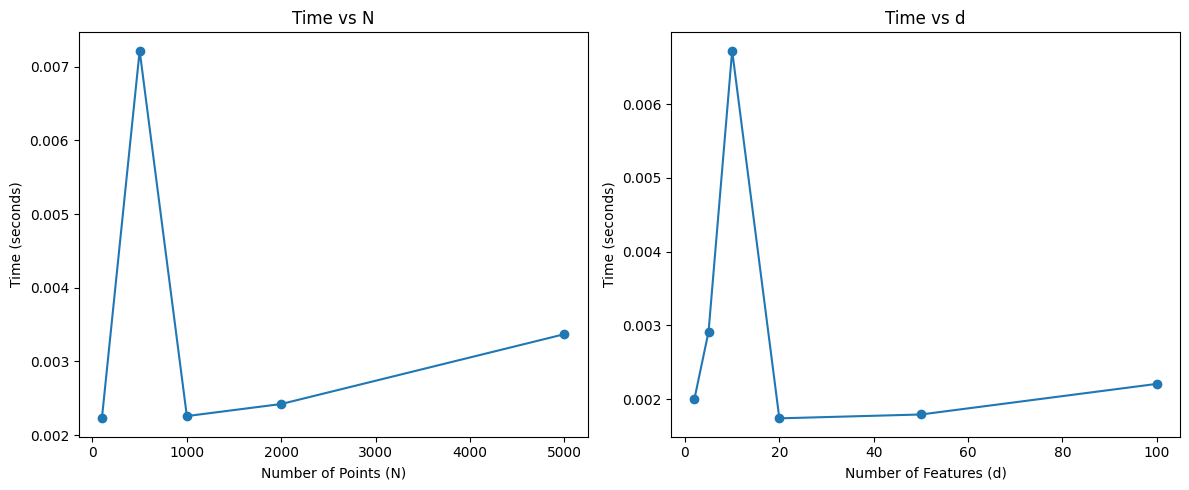

In [7]:
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

# -------------------------------
# Function to measure prediction time
# -------------------------------
def measure_time(X_train, y_train, X_test):
    knn = KNeighborsClassifier(n_neighbors=3)
    knn.fit(X_train, y_train)

    start = time.time()
    knn.predict(X_test)
    end = time.time()

    return end - start

# -------------------------------
# Experiment 1: Time vs N
# -------------------------------
N_values = [100, 500, 1000, 2000, 5000]
d_fixed = 5

times_N = []

for N in N_values:
    X_train = np.random.rand(N, d_fixed)
    y_train = np.random.randint(0, 2, N)
    X_test = np.random.rand(100, d_fixed)

    t = measure_time(X_train, y_train, X_test)
    times_N.append(t)

# -------------------------------
# Experiment 2: Time vs d
# -------------------------------
d_values = [2, 5, 10, 20, 50, 100]
N_fixed = 1000

times_d = []

for d in d_values:
    X_train = np.random.rand(N_fixed, d)
    y_train = np.random.randint(0, 2, N_fixed)
    X_test = np.random.rand(100, d)

    t = measure_time(X_train, y_train, X_test)
    times_d.append(t)

# -------------------------------
# Plotting (SIDE BY SIDE)
# -------------------------------
plt.figure(figsize=(12, 5))

# Plot 1: Time vs N
plt.subplot(1, 2, 1)
plt.plot(N_values, times_N, marker='o')
plt.xlabel("Number of Points (N)")
plt.ylabel("Time (seconds)")
plt.title("Time vs N")

# Plot 2: Time vs d
plt.subplot(1, 2, 2)
plt.plot(d_values, times_d, marker='o')
plt.xlabel("Number of Features (d)")
plt.ylabel("Time (seconds)")
plt.title("Time vs d")

plt.tight_layout()
plt.show()

### ⭐⭐⭐ Exercise 8 — "Build a KNN House-Price Estimator" 🏠
Generate 60 fake houses with `[size, bedrooms, age]` and a noisy price. Implement `knn_regress` for
multi-feature input (it already works — just pass 3-column X!). Try k=1, 5, 20 and plot predicted
vs actual price for a held-out test set. Which k gives predictions closest to the diagonal line
(perfect prediction)?

Answer:
        What Graph Shows:
          Each plot shows Actual vs Predicted prices
          Diagonal line = Perfect prediction
          Points close to line = Good model

          K = 1
            Very noisy predictions
            Points scattered far from line
            Overfitting
          K = 5
            Points close to diagonal
            Balanced predictions
            Best performance ✅
          K = 20
            Too smooth predictions
            Misses patterns
            Underfitting
            
          Final Conclusion
            K = 5 gives best predictions (closest to diagonal line)
            Small K → overfitting
            Large K → underfitting  

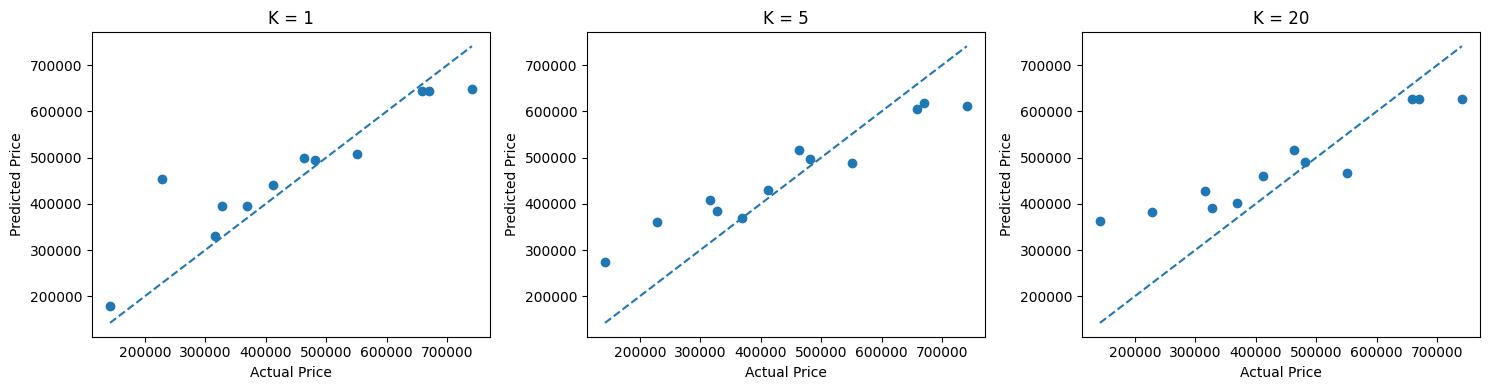

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

# -------------------------------
# Step 1: Generate fake dataset
# -------------------------------
np.random.seed(42)

N = 60

# Features: [size (sqft), bedrooms, age]
size = np.random.randint(500, 3000, N)
bedrooms = np.random.randint(1, 5, N)
age = np.random.randint(0, 30, N)

X = np.column_stack((size, bedrooms, age))

# Price formula (with noise)
price = (size * 200) + (bedrooms * 50000) - (age * 1000) + np.random.randn(N) * 20000

# -------------------------------
# Step 2: Train-Test Split (80/20)
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, price, test_size=0.2, random_state=42)

# -------------------------------
# Step 3: Try different K values
# -------------------------------
k_values = [1, 5, 20]

plt.figure(figsize=(15, 4))

for i, k in enumerate(k_values):
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)

    # -------------------------------
    # Plot Predicted vs Actual
    # -------------------------------
    plt.subplot(1, 3, i+1)
    plt.scatter(y_test, y_pred)

    # Perfect prediction line (diagonal)
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], linestyle='--')

    plt.xlabel("Actual Price")
    plt.ylabel("Predicted Price")
    plt.title(f"K = {k}")

plt.tight_layout()
plt.show()